# 01 · Colab·LLM 코딩과 의약품 제조 데이터 이해
### 실습으로 배우는 GMP AI — 강의 목차 ①·②·③ 연계

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/GMPAI/blob/main/01_Colab_LLM_GMP_Data.ipynb)

| 항목 | 내용 |
|---|---|
| **목차 연계** | ① 의약품 제조와 AI 도입 범위 · ② 제조 데이터의 이해(QbD·CPP·CQA·PAT) · ③ LLM 코딩으로 만드는 AI 모델 |
| **학습 목표** | Colab 사용법, LLM 코딩 워크플로우, **실제 제조 배치 데이터**로 QbD 용어(QTPP·CQA·CPP)를 데이터와 연결, EDA·OOS 판정 |
| **데이터** | **실제 제약공장 정제 생산 1,005 배치** (Lek Pharmaceuticals / 슬로베니아, *Scientific Data* 2022 공개, CC BY 4.0) |
| **실행 환경** | CPU · 약 15분 |

> 이 과정의 모든 예제는 **실제 또는 공인 시뮬레이션 제조 데이터**를 사용합니다.
> 가상의 난수 데이터가 아니라 **진짜 공장 데이터의 지저분함(결측·드리프트·불균형)** 을 다루는 것이 목표입니다.

## 0. Colab 기초
- 브라우저만으로 쓰는 **무료 파이썬 환경** (구글 계정 필요), 설치 불필요
- 셀 실행: **`Shift + Enter`**
- 라이브러리 설치: `%pip install 이름`
- **[런타임] → [런타임 유형 변경]** 에서 GPU(T4) 선택 가능 (예제 07 비전검사에서 사용)
- 회사 보안 정책상 외부 클라우드 사용이 제한되면, 같은 코드를 사내 Jupyter/Anaconda 에서 그대로 실행할 수 있습니다.

In [1]:
%pip install -q koreanize-matplotlib
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
import warnings; warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
print("✅ 준비 완료 — pandas", pd.__version__)

Note: you may need to restart the kernel to use updated packages.


✅ 준비 완료 — pandas 3.0.6


## 1. 의약품 제조와 AI — 어디에 쓰는가
| 영역 | AI 활용 | 이 과정의 예제 |
|---|---|---|
| **공정 모니터링** | 실시간 이상 감지, 다변량 SPC | 예제 03·06 |
| **품질 예측** | CQA 예측, **OOS 조기경보** | 예제 02·04·05 |
| **PAT·RTRT** | 소프트센서(인라인 분석), 실시간 출하시험 | 예제 09 |
| **외관 검사** | 딥러닝 비전 (정제·바이알 결함) | 예제 07 |
| **설비 관리** | 예지보수(RUL 예측) | 예제 10 |
| **QMS 자동화** | 일탈(Deviation) 분류, CAPA 효과 분석 | 예제 06 |
| **규제 대응** | 모델 검증, 감사추적, 드리프트 모니터링 | 예제 08 |

### 왜 지금인가
1. **규제 환경**: ICH Q8–Q10·Q13, FDA PAT 가이던스, FDA 의 AI 활용 논의(2023 Discussion Paper → 2025 가이던스 초안) 등 규제기관이 AI 적용 틀을 구체화
2. **데이터 인프라**: LIMS·MES·Historian 디지털화로 학습 가능한 데이터 축적
3. **경제성**: 배치 실패·재작업·일탈 조사 비용 절감, 출시 기간 단축

## 2. ⭐ 제조 데이터의 뼈대 — QbD 용어
| 약자 | 영문 | 의미 | 예 (정제) |
|---|---|---|---|
| **QTPP** | Quality Target Product Profile | 목표 제품 품질 프로파일 | "경구 정제, 30분 내 80% 이상 용출" |
| **CQA** | Critical Quality Attribute | **중요 품질 특성** (결과) | 용출률, 함량균일성, 불순물, 경도 |
| **CPP** | Critical Process Parameter | **중요 공정 변수** (원인, 조절 가능) | 타정 압력, 타정 속도, 충전 깊이 |
| **CMA** | Critical Material Attribute | 중요 원료 특성 | 원료 입도, 수분, 순도 |
| **PAT** | Process Analytical Technology | 공정분석기술 (인라인 측정) | NIR·Raman 실시간 분석 |
| **Design Space** | — | CQA 를 만족하는 CPP 의 허용 범위 | 압력 10~14 kN, 속도 80~110 krpm |

```
       CMA(원료)  ─┐
                   ├─→  CPP(공정)  ─→  CQA(품질)  ─→  QTPP(제품 목표)
       환경·설비  ─┘
          ↑ AI 가 배우는 관계: f(CMA, CPP) → CQA
```
> **AI 모델링 관점**: X = CMA + CPP (공정 중 알 수 있는 값) / y = CQA (나중에 시험실에서 측정되는 값)
> → 모델이 정확하면 **시험 전에 품질을 예측**할 수 있고, 이것이 **RTRT(실시간 출하시험)** 의 기반입니다.

## 3. 실제 제조 데이터 불러오기
**데이터 출처**: Žagar & Mihelič, *Scientific Data* 9:55 (2022) — 슬로베니아 Lek(산도스) 공장의 **실제 정제 생산 1,005 배치**
- 원료 시험 결과(API·유당·전분·SMCC) + 타정 공정 데이터 + **최종 품질시험 결과**
- 제품 코드 25종, 함량 4종(5·10·20·40 mg), 배치 크기 24만~192만 정
- 기간: 2018년 11월 ~ 2021년 4월

In [2]:
REPO = "https://raw.githubusercontent.com/StillWork/GMPAI/main/data/"
def load_data(name, **kw):
    local = os.path.join("data", name)
    return pd.read_csv(local if os.path.exists(local) else REPO + name, **kw)

df = load_data("tablet_batches.csv", parse_dates=["start_date"])
print("배치 수 × 변수 수:", df.shape)
print("기간:", df.start_date.min().date(), "~", df.start_date.max().date())
print("제품 코드:", df.code.nunique(), "종 / 함량:", df.strength.unique().tolist())
df.head(3)

배치 수 × 변수 수: (1005, 83)
기간: 2018-11-01 ~ 2021-04-01
제품 코드: 25 종 / 함량: ['5MG', '10M', '20M', '40M']


,batch,code,strength,size,start,api_code,api_batch,smcc_batch,lactose_batch,starch_batch,...,stiffness_mean,stiffness_max,stiffness_min,ejection_mean,ejection_max,ejection_min,Startup_tbl_fill_maxDifference,Startup_main_CompForce_mean,Startup_tbl_fill_mean,start_date
0,1,25,5MG,240000,nov.18,5,2,1,2,1,...,91.016149,103,67,223.319255,248,196,0.38,4.587500,5.466667,2018-11-01
1,2,25,5MG,240000,nov.18,5,2,1,2,1,...,88.223827,103,77,215.963899,252,194,0.18,4.390909,5.315455,2018-11-01
2,3,25,5MG,240000,nov.18,5,2,1,2,1,...,88.967819,111,72,212.530393,248,184,0.12,4.430000,5.242000,2018-11-01


### 변수 구성 — 무엇이 CMA·CPP·CQA 인가

In [3]:
CQA = ["dissolution_av", "dissolution_min", "impurities_total", "impurity_o", "impurity_l", "residual_solvent"]
CMA = [c for c in df.columns if c.startswith(("api_", "lactose_", "smcc_", "starch_")) and not c.endswith("_batch")]
CPP = ["tbl_speed_mean", "tbl_speed_change", "main_CompForce mean", "main_CompForce_sd", "pre_CompForce_mean",
       "tbl_fill_mean", "tbl_fill_sd", "cyl_height_mean", "SREL_production_mean", "SREL_production_max",
       "stiffness_mean", "ejection_mean", "total_waste", "startup_waste", "fom_mean", "tbl_speed_0_duration"]
IPC = ["tbl_min_weight", "tbl_max_weight", "tbl_rsd_weight", "tbl_min_hardness", "tbl_max_hardness", "tbl_av_hardness",
       "tbl_min_thickness", "tbl_max_thickness", "tbl_tensile", "fct_av_hardness", "fct_tensile", "batch_yield"]
print(f"CMA(원료 특성) {len(CMA)}개: {CMA[:6]} ...")
print(f"CPP(공정 변수) {len(CPP)}개: {CPP[:6]} ...")
print(f"공정 중 시험(IPC) {len(IPC)}개: {IPC[:5]} ...")
print(f"CQA(최종 품질) {len(CQA)}개: {CQA}")
df[CQA].describe().round(2)

CMA(원료 특성) 20개: ['api_code', 'api_water', 'api_total_impurities', 'api_l_impurity', 'api_content', 'api_ps01'] ...
CPP(공정 변수) 16개: ['tbl_speed_mean', 'tbl_speed_change', 'main_CompForce mean', 'main_CompForce_sd', 'pre_CompForce_mean', 'tbl_fill_mean'] ...
공정 중 시험(IPC) 12개: ['tbl_min_weight', 'tbl_max_weight', 'tbl_rsd_weight', 'tbl_min_hardness', 'tbl_max_hardness'] ...
CQA(최종 품질) 6개: ['dissolution_av', 'dissolution_min', 'impurities_total', 'impurity_o', 'impurity_l', 'residual_solvent']


,dissolution_av,dissolution_min,impurities_total,impurity_o,impurity_l,residual_solvent
count,1005.00,1005.00,1005.00,1005.00,1005.00,1005.00
mean,90.65,85.59,0.14,0.05,0.07,0.05
std,3.37,4.23,0.10,0.01,0.03,0.04
min,82.50,74.00,0.05,0.00,0.05,0.00
25%,88.33,83.00,0.05,0.05,0.05,0.02
50%,90.33,85.00,0.09,0.05,0.05,0.03
75%,92.83,88.00,0.23,0.05,0.09,0.06
max,102.67,100.00,0.60,0.16,0.20,0.24


| CQA | 의미 | 시험법 |
|---|---|---|
| `dissolution_av` | 30분 용출률 평균 (%) | 용출시험(USP) |
| `dissolution_min` | 6정 중 **최솟값** (%) | 개별 정제 — 규격 판정의 핵심 |
| `impurities_total` | 총 불순물 (%) | HPLC |
| `impurity_o`, `impurity_l` | 개별 불순물 | HPLC |
| `residual_solvent` | 잔류 용매 | GC |

## 4. 데이터 품질 점검 — 실제 데이터는 깨끗하지 않다
AI 프로젝트의 70%는 데이터 정리입니다. **결측·이상치·단위 오류**를 먼저 확인합니다. (ALCOA+ 의 *Complete·Accurate* 와 직결)

결측이 있는 열:
tbl_min_weight          10
tbl_max_weight          10
api_l_impurity           9
api_total_impurities     5
api_content              2

전체 결측률: 0.04%


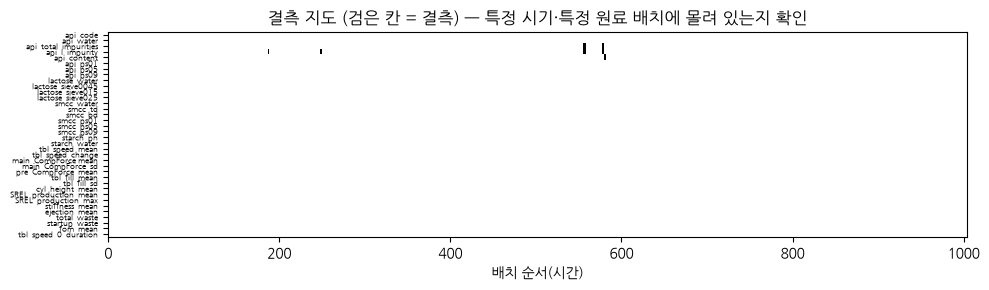

In [4]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print("결측이 있는 열:")
print(miss.to_string())
print(f"\n전체 결측률: {df.isna().mean().mean():.2%}")
plt.figure(figsize=(10, 3))
plt.imshow(df[CMA + CPP].isna().T.values, aspect="auto", cmap="Greys", interpolation="nearest")
plt.yticks(range(len(CMA + CPP)), CMA + CPP, fontsize=6); plt.xlabel("배치 순서(시간)")
plt.title("결측 지도 (검은 칸 = 결측) — 특정 시기·특정 원료 배치에 몰려 있는지 확인"); plt.tight_layout(); plt.show()

## 5. CQA 분포와 규격(Specification) — OOS·OOT 판정
- **규격(Specification)**: 제품이 반드시 만족해야 하는 기준 (허가 사항) → 벗어나면 **OOS**(Out of Specification)
- **관리한계(Control Limit)**: 공정의 통계적 변동 범위 (예제 03) → 벗어나면 **OOT**(Out of Trend) 조사 대상
- 둘은 **다릅니다**: 규격은 제품 기준, 관리한계는 공정 기준

여기서는 교육용으로 USP 용출시험 기준을 단순화해 **최소 용출률 80%** 를 규격으로 가정합니다.

OOS 배치: 50건 / 1005건 = 5.0%


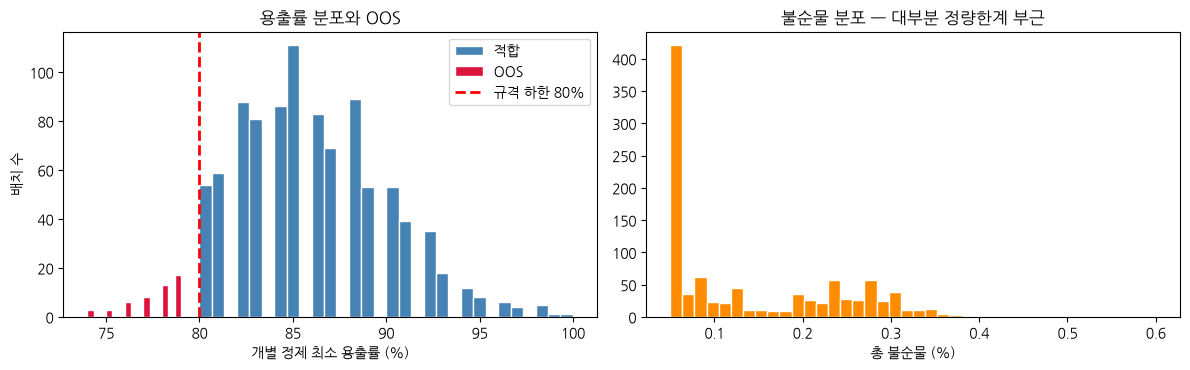

In [5]:
SPEC_Q = 80          # 교육용 가정: 개별 정제 용출률 하한 (Q=80%)
df["OOS"] = df["dissolution_min"] < SPEC_Q
print(f"OOS 배치: {df.OOS.sum()}건 / {len(df)}건 = {df.OOS.mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(df.loc[~df.OOS, "dissolution_min"], bins=30, color="steelblue", edgecolor="white", label="적합")
ax[0].hist(df.loc[df.OOS, "dissolution_min"], bins=15, color="crimson", edgecolor="white", label="OOS")
ax[0].axvline(SPEC_Q, color="red", ls="--", lw=2, label=f"규격 하한 {SPEC_Q}%")
ax[0].set_xlabel("개별 정제 최소 용출률 (%)"); ax[0].set_ylabel("배치 수"); ax[0].legend(); ax[0].set_title("용출률 분포와 OOS")
ax[1].hist(df["impurities_total"], bins=40, color="darkorange", edgecolor="white")
ax[1].set_xlabel("총 불순물 (%)"); ax[1].set_title("불순물 분포 — 대부분 정량한계 부근")
plt.tight_layout(); plt.show()

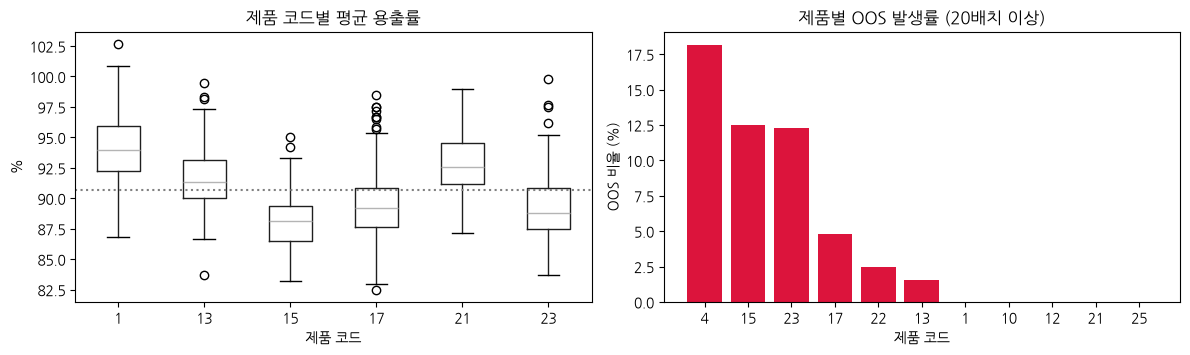

→ 제품마다 OOS 위험이 다릅니다. AI 모델도 제품별로 나누거나 제품 정보를 특성으로 넣어야 합니다.


In [6]:
# 제품 코드별 품질 차이 — 같은 공장이라도 제품마다 공정·규격이 다르다
big = df.code.value_counts().head(6).index
sub = df[df.code.isin(big)]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sub.boxplot(column="dissolution_av", by="code", ax=ax[0], grid=False)
ax[0].axhline(df.dissolution_av.mean(), color="gray", ls=":"); ax[0].set_title("제품 코드별 평균 용출률"); ax[0].set_xlabel("제품 코드"); ax[0].set_ylabel("%")
rate = df.groupby("code")["OOS"].agg(["mean", "size"]).query("size >= 20").sort_values("mean", ascending=False)
ax[1].bar(rate.index.astype(str), rate["mean"] * 100, color="crimson")
ax[1].set_xlabel("제품 코드"); ax[1].set_ylabel("OOS 비율 (%)"); ax[1].set_title("제품별 OOS 발생률 (20배치 이상)")
plt.suptitle(""); plt.tight_layout(); plt.show()
print("→ 제품마다 OOS 위험이 다릅니다. AI 모델도 제품별로 나누거나 제품 정보를 특성으로 넣어야 합니다.")

## 6. 시간 추이 — 공정은 변한다 (드리프트)
2년 반의 생산 기록을 시간순으로 보면 **원료 로트 교체, 설비 정비, 공정 변경**의 흔적이 보입니다.
→ 이것이 **연속공정검증(CPV)** 의 대상이자, AI 모델이 시간이 지나면 성능이 떨어지는(드리프트) 이유입니다.

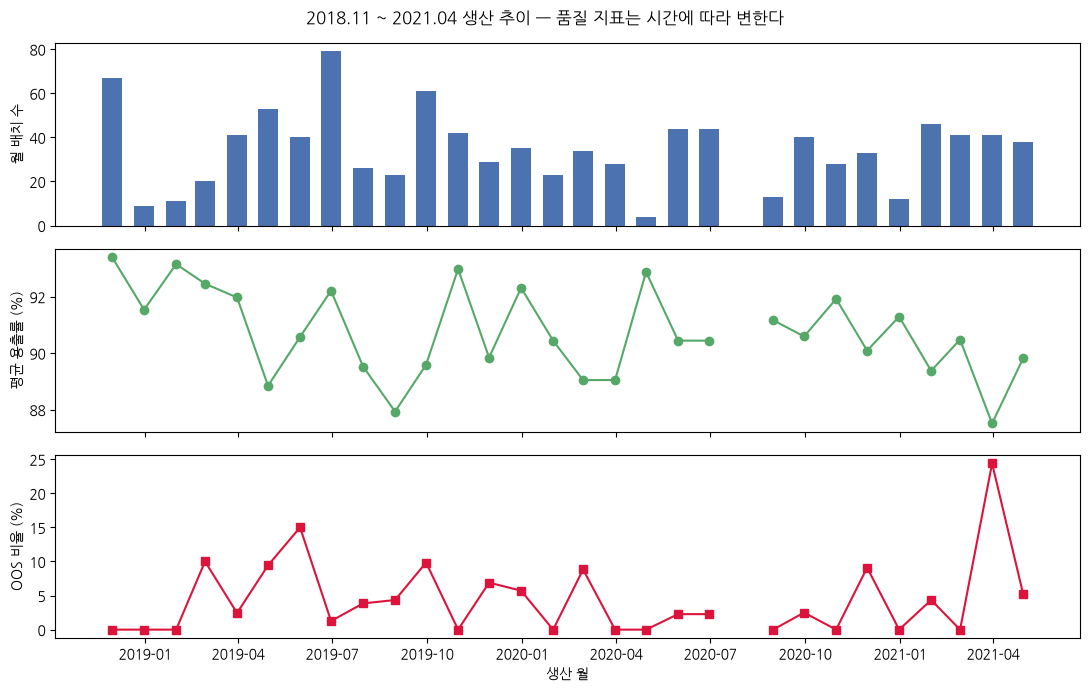

In [7]:
monthly = df.set_index("start_date").resample("ME").agg(
    배치수=("batch", "size"), 평균용출=("dissolution_av", "mean"), OOS율=("OOS", "mean"), 평균압력=("main_CompForce mean", "mean"))
fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
ax[0].bar(monthly.index, monthly["배치수"], width=20, color="#4C72B0"); ax[0].set_ylabel("월 배치 수")
ax[1].plot(monthly.index, monthly["평균용출"], "o-", color="#55A868"); ax[1].set_ylabel("평균 용출률 (%)")
ax[2].plot(monthly.index, monthly["OOS율"] * 100, "s-", color="crimson"); ax[2].set_ylabel("OOS 비율 (%)"); ax[2].set_xlabel("생산 월")
plt.suptitle("2018.11 ~ 2021.04 생산 추이 — 품질 지표는 시간에 따라 변한다"); plt.tight_layout(); plt.show()

## 7. ⭐ 상관관계 분석 = QbD 리스크 평가의 데이터 버전
ICH Q9 의 **위험 평가(Risk Assessment)** 는 "어떤 변수가 품질에 영향을 주는가"를 찾는 작업입니다.
전문가 경험(FMEA)에 더해, **데이터로 CPP–CQA 관계를 정량화**할 수 있습니다.

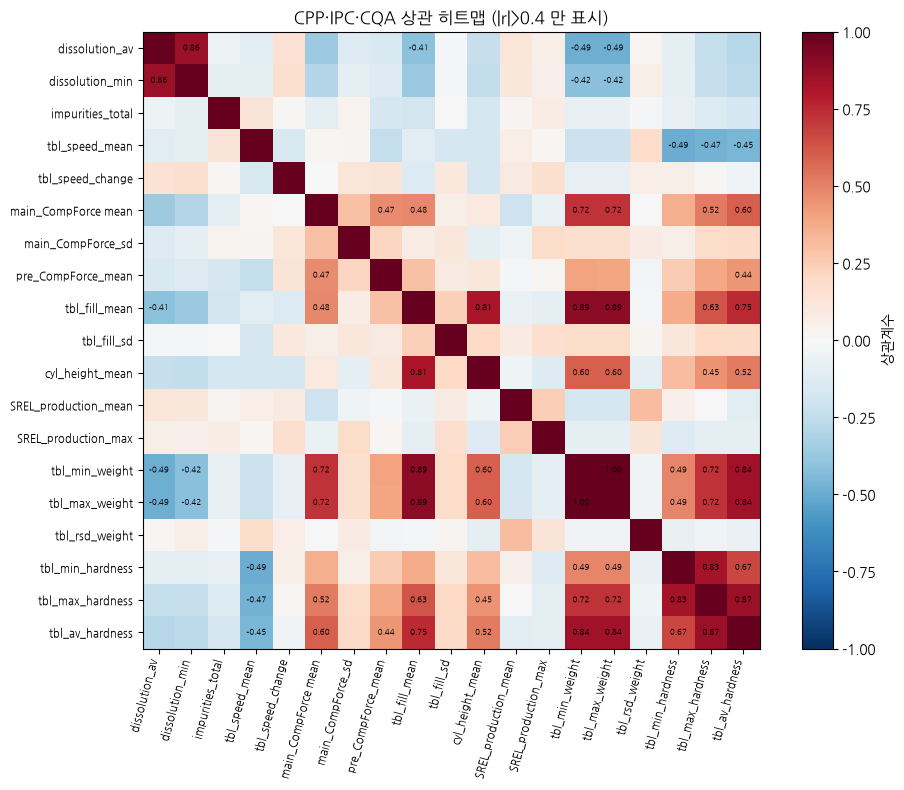

In [8]:
cols = ["dissolution_av", "dissolution_min", "impurities_total"] + [c for c in CPP if c in df.columns][:10] + IPC[:6]
corr = df[cols].corr(numeric_only=True)
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(cols)), cols, rotation=75, ha="right", fontsize=8); plt.yticks(range(len(cols)), cols, fontsize=8)
plt.colorbar(label="상관계수")
for i in range(len(cols)):
    for j in range(len(cols)):
        if abs(corr.values[i, j]) > 0.4 and i != j:
            plt.text(j, i, f"{corr.values[i,j]:.2f}", ha="center", va="center", fontsize=6)
plt.title("CPP·IPC·CQA 상관 히트맵 (|r|>0.4 만 표시)"); plt.tight_layout(); plt.show()

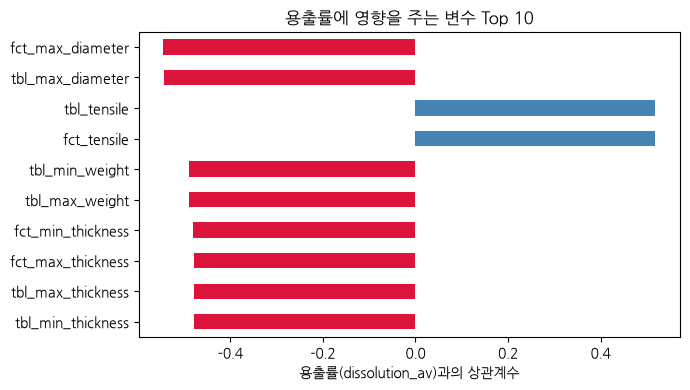

⚠️ 상관관계는 인과관계가 아닙니다. 공정 이해와 DoE 로 확인해야 합니다 (ICH Q8 Design Space).


In [9]:
# 용출률과 가장 강하게 연관된 변수 Top 10 (절댓값 기준)
num = df.select_dtypes("number").drop(columns=["batch", "code", "size"], errors="ignore")
rel = num.corrwith(df["dissolution_av"]).drop(CQA, errors="ignore").dropna()
top = rel.reindex(rel.abs().sort_values(ascending=False).index).head(10)
top[::-1].plot.barh(figsize=(7, 4), color=["crimson" if v < 0 else "steelblue" for v in top[::-1]])
plt.xlabel("용출률(dissolution_av)과의 상관계수"); plt.title("용출률에 영향을 주는 변수 Top 10"); plt.tight_layout(); plt.show()
print("⚠️ 상관관계는 인과관계가 아닙니다. 공정 이해와 DoE 로 확인해야 합니다 (ICH Q8 Design Space).")

## 8. ⭐ LLM 코딩 워크플로우 — 파이썬을 몰라도 분석할 수 있다
```
문제 정의 → 프롬프트 작성 → LLM(Gemini/Claude) 코드 생성 → Colab 실행 → 결과 검증 → 오류 수정 요청
```
### 좋은 프롬프트의 4요소
| 요소 | 예시 |
|---|---|
| **역할·맥락** | "너는 파이썬 데이터 분석 튜터야. 나는 제약 QA 담당자이고 파이썬 초보야." |
| **데이터 설명** | "df 에 1005개 배치가 있고 열은 code, start_date, dissolution_av, dissolution_min, main_CompForce mean 등이야." |
| **구체적 요청** | "제품 코드 17의 월별 평균 용출률 추이를 선그래프로 그려줘." |
| **형식·제약** | "한글 주석을 달고 matplotlib 으로, 그래프 제목은 한글로." |

> **GMP 현장 주의**: 사내 데이터·배치 기록을 외부 LLM 에 직접 붙여넣지 마세요.
> **열 이름과 구조만 설명**하고 코드를 받아 사내에서 실행하는 것이 안전합니다.

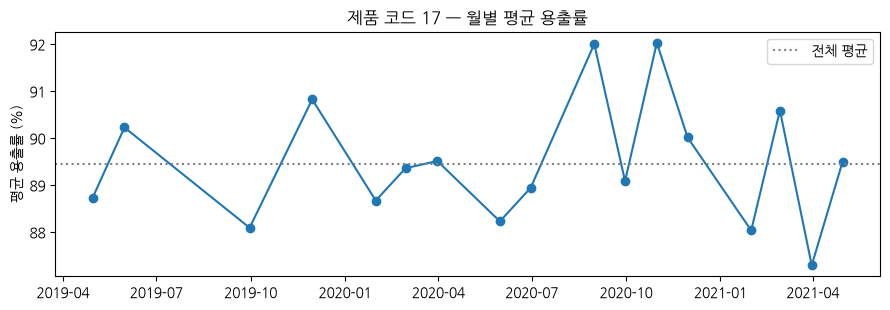

In [10]:
# 👇 LLM 이 만들어 줄 법한 코드 — 실행해서 '결과가 말이 되는지' 검증합니다
c17 = df[df.code == 17].set_index("start_date").sort_index()
m = c17["dissolution_av"].resample("ME").mean().dropna()
plt.figure(figsize=(9, 3.2))
plt.plot(m.index, m.values, "o-")
plt.axhline(c17["dissolution_av"].mean(), color="gray", ls=":", label="전체 평균")
plt.ylabel("평균 용출률 (%)"); plt.title("제품 코드 17 — 월별 평균 용출률"); plt.legend(); plt.tight_layout(); plt.show()

### 🔁 실습: 여러분 차례입니다
아래 프롬프트를 LLM 에 넣고, 받은 코드를 다음 셀에 붙여 실행해 보세요.
```
너는 친절한 파이썬 데이터 분석 튜터야. 나는 파이썬이 처음인 제약회사 품질관리 담당자야.
pandas 데이터프레임 df 에 제약공장 정제 생산 1005배치 데이터가 있어.
주요 열: code(제품코드), strength(함량), start_date(생산월), dissolution_av(평균 용출률),
dissolution_min(최소 용출률), impurities_total(총 불순물), 'main_CompForce mean'(평균 타정압력),
tbl_speed_mean(평균 타정속도), batch_yield(수율).
함량(strength)별로 평균 용출률과 OOS 비율(dissolution_min < 80 기준)을 계산해서 표로 출력하고,
막대그래프로도 보여줘. 코드에는 한글 주석을 달아줘.
```
> **검증 습관**: 에러가 나면 **에러 메시지를 그대로 복사해 LLM 에 붙여넣고** "이 에러 고쳐줘"라고 하세요.
> LLM 은 존재하지 않는 열 이름이나 함수를 만들어낼 수 있으므로 **결과를 반드시 눈으로 확인**합니다.

In [11]:
# ✏️ 여기에 LLM 에게 받은 코드를 붙여넣고 실행하세요

## 9. 데이터 무결성(Data Integrity) 관점에서 본 EDA
| ALCOA+ 원칙 | EDA 에서 확인할 것 |
|---|---|
| **A**ttributable (귀속) | 배치번호·원료 로트·생산일자가 모두 기록되어 있는가 |
| **L**egible (판독) | 열 이름·단위가 명확한가 (예: 압력 kN, 속도 krpm) |
| **C**ontemporaneous (동시) | 타임스탬프가 공정 순서와 일치하는가 |
| **O**riginal (원본) | 원시 데이터를 보존하고, 가공본은 별도 저장했는가 |
| **A**ccurate (정확) | 이상치가 측정 오류인지 실제 공정 이상인지 구분했는가 |
| **+ Complete** | 실패·재시험 배치를 임의로 제외하지 않았는가 ← **AI 에서 특히 중요** |

> ⚠️ **AI 관점의 함정**: 불량 배치를 "노이즈"라며 삭제하면 모델은 **불량을 영원히 예측하지 못합니다.**
> 데이터 삭제는 반드시 근거를 기록해야 하며(원본 보존), 이는 규제 실사의 단골 점검 항목입니다.

In [12]:
# 간단한 데이터 무결성 점검 함수 — 예제 08(AI 검증·규제)에서 확장합니다
def integrity_check(d):
    issues = []
    if d["batch"].duplicated().any(): issues.append("중복 배치번호 존재")
    if d["dissolution_av"].gt(110).any(): issues.append("용출률 110% 초과 (측정/입력 오류 의심)")
    if d["batch_yield"].gt(100).any(): issues.append(f"수율 100% 초과 배치 {int(d['batch_yield'].gt(100).sum())}건")
    if d.isna().mean().max() > 0.05: issues.append(f"결측률 5% 초과 열: {d.isna().mean().idxmax()}")
    neg = d.select_dtypes('number').lt(0).any()
    if neg.any(): issues.append(f"음수 값이 있는 열: {list(neg[neg].index)[:3]}")
    return issues or ["특이사항 없음"]

for s in integrity_check(df): print(" •", s)

 • 수율 100% 초과 배치 2건


## ✅ 정리
| 배운 것 | 핵심 |
|---|---|
| Colab + LLM 코딩 | 문제 정의 → 프롬프트 → 실행 → **검증**. 사내 데이터는 구조만 설명 |
| QbD 용어 | CMA·CPP → CQA 관계를 AI 가 학습: **X = 공정 중 아는 값, y = 나중에 측정되는 품질** |
| 실제 제조 데이터 | 결측·제품별 차이·시간 드리프트가 있는 것이 정상 |
| EDA | 규격(OOS) vs 관리한계(OOT) 구분, 상관분석 = QbD 리스크 평가의 데이터 버전 |
| 데이터 무결성 | 불량 데이터를 지우면 AI 는 불량을 배우지 못한다 |

➡️ **다음 예제 02**: 이 데이터로 **회귀·분류 모델을 만들고 성능을 올바르게 측정**하는 법 (머신러닝 기초)